# PS 02 exploratory analysis and synthetic evaluation

This notebook reproduces the supplied-data EDA, shows frozen synthetic results and reruns artifact invariants. It does not call an LLM or deploy an application. The original CSV has point labels without incident onset; synthetic warning times are a separate experiment. Install `requirements-analysis.txt` in a clean Python 3.12 environment before running. Select that environment as the kernel; the custom kernel label in this saved execution is only the authoring environment.

In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / "data/raw/ps02_system_telemetry.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/raw/ps02_system_telemetry.csv").exists(), "Run from package root or notebooks directory"
sys.path.insert(0, str(ROOT))
from src.eda import run
summary = run()
print("Source SHA-256:", summary["source_sha256"])
print("No source timezone was assumed.")

{
  "rows": 500,
  "incident_count": 28,
  "series_median_gap_hours": 50.7225,
  "baseline_all": [
    {
      "split": "all_exploratory",
      "detector": "exceed_supplied_threshold",
      "n": 500,
      "tp": 0,
      "fp": 0,
      "fn": 28,
      "tn": 472,
      "precision": null,
      "recall": 0.0,
      "f1": 0.0,
      "fpr": 0.0,
      "recall_wilson": [
        0.0,
        0.12064720365810762
      ],
      "fpr_wilson": [
        0.0,
        0.008073274804052441
      ]
    },
    {
      "split": "all_exploratory",
      "detector": "ratio_ge_0.75",
      "n": 500,
      "tp": 28,
      "fp": 301,
      "fn": 0,
      "tn": 171,
      "precision": 0.0851063829787234,
      "recall": 1.0,
      "f1": 0.1568627450980392,
      "fpr": 0.6377118644067796,
      "recall_wilson": [
        0.8793527963418923,
        1.0
      ],
      "fpr_wilson": [
        0.5933976634310759,
        0.6798024939322146
      ]
    },
    {
      "split": "all_exploratory",
      "detect

## Distributions and coverage

Rows are isolated service/metric observations. Global summaries for value and threshold pool unestablished units; do not use those means as system capacity. The target is binary, so IQR flags on its positive class are not data errors.

,column,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,missing,nonfinite,iqr_outliers
0,value,500.0,54.26546,25.529387,10.38,10.7093,14.685,31.7775,56.01,75.8725,93.5215,96.9928,97.76,-0.058520,0,0,0
1,threshold,500.0,67.94508,32.571830,11.29,13.4943,18.726,38.3575,68.93,93.1850,120.3855,132.1132,134.29,0.055176,0,0,0
2,user_count_active,500.0,2515.42200,1476.838484,10.00,29.9700,257.650,1180.0000,2607.50,3855.5000,4748.7500,4952.1700,4998.00,-0.033682,0,0,0
3,error_count_last_hour,500.0,25.02600,13.813869,0.00,0.0000,3.000,14.0000,25.00,36.0000,47.0000,50.0000,50.00,-0.067184,0,0,0
4,response_time_ms,500.0,1578.17200,872.635987,25.00,50.9600,172.600,796.7500,1642.50,2323.7500,2861.0500,2979.0200,2998.00,-0.130089,0,0,0
5,is_incident,500.0,0.05600,0.230152,0.00,0.0000,0.000,0.0000,0.00,0.0000,1.0000,1.0000,1.00,3.873815,0,0,28


,column,category,count,proportion
0,service_name,AnalyticsDashboard,71,0.142
1,service_name,SearchAPI,66,0.132
2,service_name,NotificationHub,64,0.128
3,service_name,AuthService,63,0.126
4,service_name,ReportGenerator,61,0.122
5,service_name,PaymentGateway,61,0.122
6,service_name,UserProfileService,59,0.118
7,service_name,DataPipeline,55,0.110
8,metric_type,connection_pool,83,0.166
9,metric_type,memory_usage,76,0.152


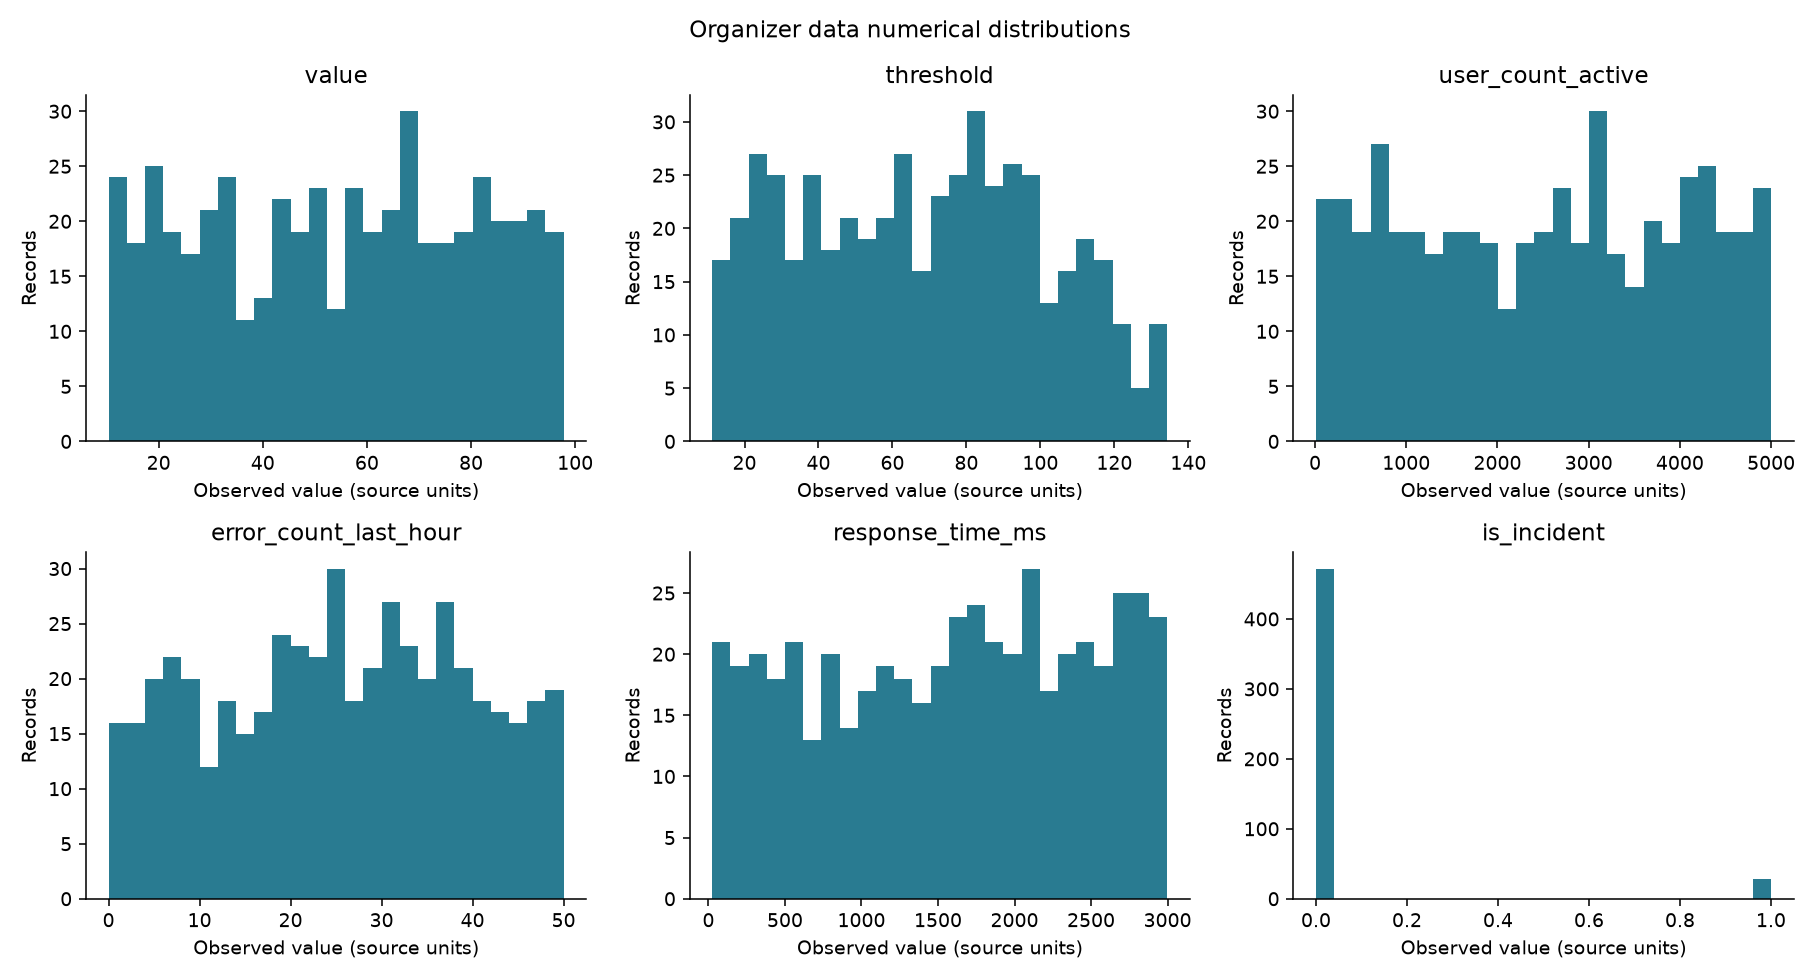

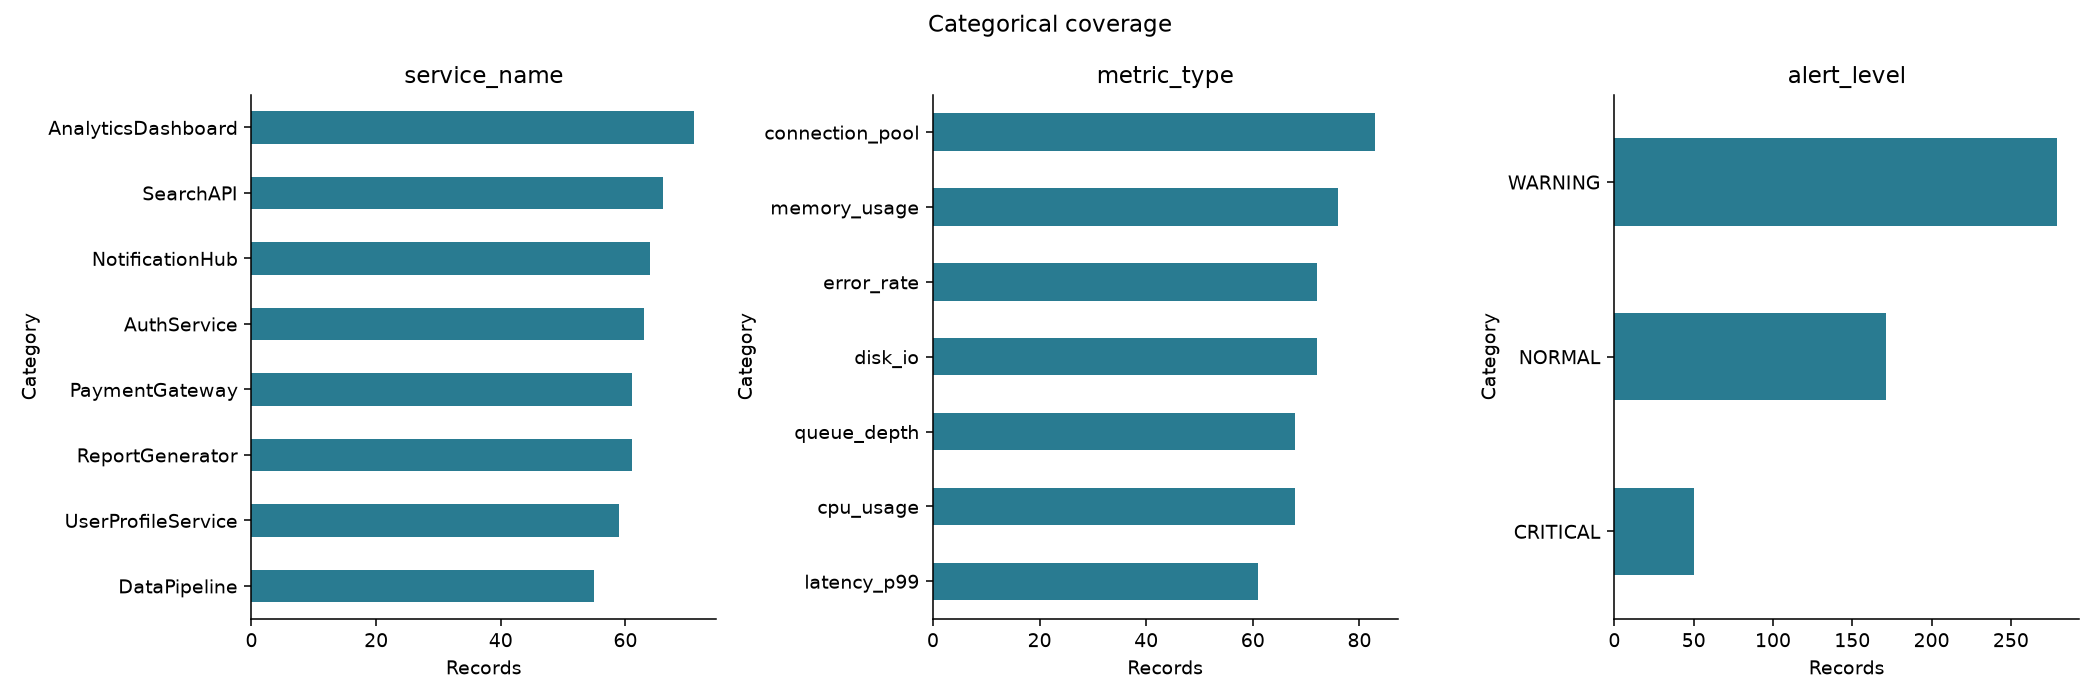

In [2]:
display(pd.read_csv(ROOT / "reports/eda/column_statistics.csv"))
display(pd.read_csv(ROOT / "reports/eda/categorical_distributions.csv"))
display(Image(filename=str(ROOT / "reports/eda/figures/numeric_distributions.png")))
display(Image(filename=str(ROOT / "reports/eda/figures/categorical_coverage.png")))

## Time and label structure

Timestamp uniqueness does not imply periodic sampling. The median service/metric median gap is about 50.7 hours. Value/threshold bands reproduce alert levels; all incident positives occur in CRITICAL. These are contemporaneous diagnostic results, not advance prediction.

,n,gap_min_seconds,gap_median_seconds,gap_max_seconds
count,56.000000,56.000000,56.000000,5.600000e+01
mean,8.928571,46878.767857,218430.910714,6.842470e+05
std,2.675526,49030.582689,128826.188370,2.449560e+05
min,3.000000,269.000000,46249.000000,3.514030e+05
25%,7.750000,9372.000000,128018.250000,5.370728e+05
50%,9.000000,25307.000000,182601.000000,6.150140e+05
75%,10.000000,67556.500000,294548.125000,7.632050e+05
max,15.000000,178884.000000,702500.000000,1.272406e+06


,feature,positive_mean,negative_mean,positive_median,negative_median,cohens_d,rank_biserial,mw_p
0,value,63.469286,53.719470,69.415000,55.205000,0.383005,0.222079,4.827594e-02
1,threshold,65.159286,68.110339,71.300000,68.715000,-0.090530,-0.048048,6.695560e-01
2,user_count_active,2210.142857,2533.531780,2401.000000,2632.000000,-0.219033,-0.128481,2.533362e-01
3,error_count_last_hour,23.214286,25.133475,21.500000,25.000000,-0.138864,-0.088756,4.300512e-01
4,response_time_ms,1830.857143,1563.182203,2079.500000,1619.500000,0.307202,0.175999,1.175822e-01
5,ratio,0.974972,0.795625,0.976894,0.781248,2.130683,0.947337,3.553227e-17


,feature,chi_square,p_value,cramers_v,minimum_expected
0,service_name,4.138225,7.637261e-01,0.090975,3.080
1,metric_type,3.318417,7.679505e-01,0.081467,3.416
2,alert_level,266.949153,1.078271e-58,0.730683,2.800


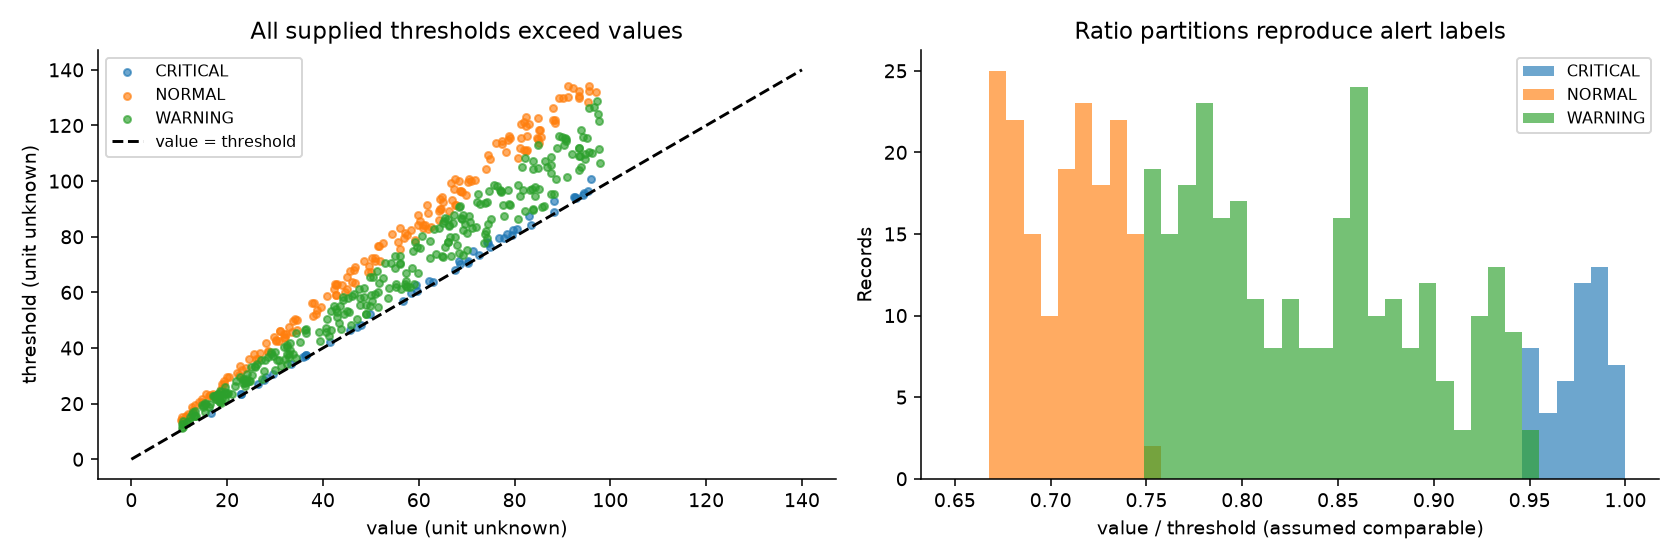

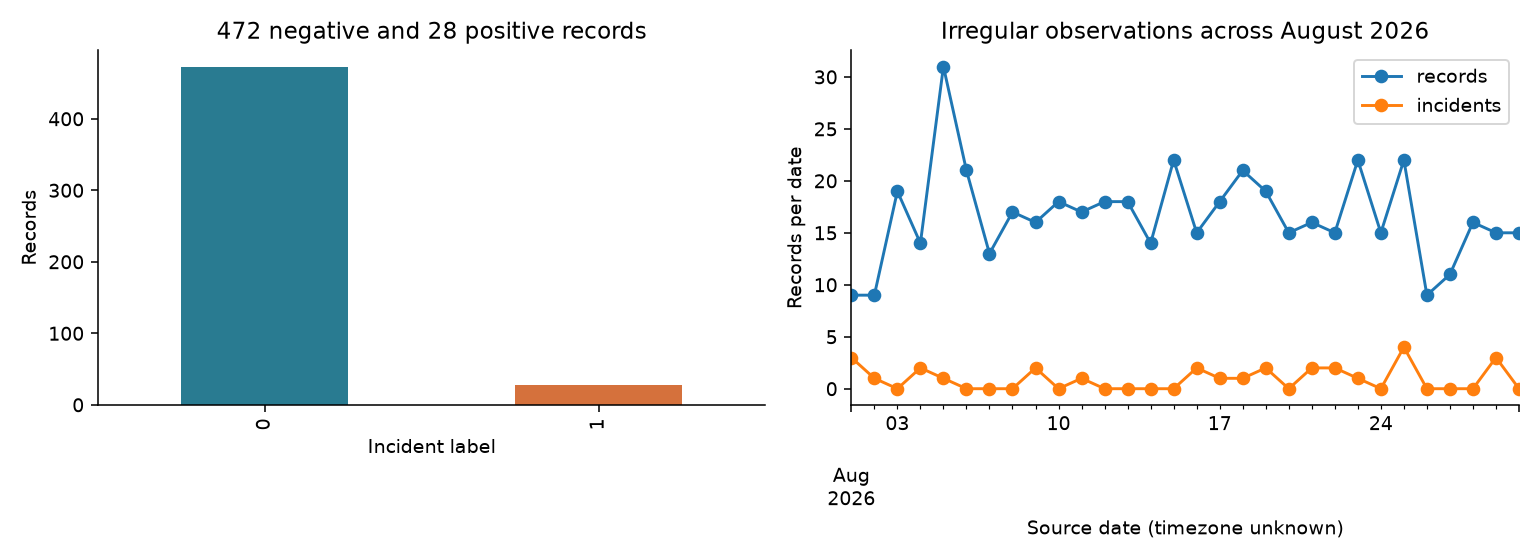

In [3]:
display(pd.read_csv(ROOT / "reports/eda/temporal_series_statistics.csv").describe())
display(pd.read_csv(ROOT / "reports/eda/incident_effect_sizes.csv"))
display(pd.read_csv(ROOT / "reports/eda/categorical_associations.csv"))
display(Image(filename=str(ROOT / "reports/eda/figures/threshold_label_structure.png")))
display(Image(filename=str(ROOT / "reports/eda/figures/class_balance_and_timeline.png")))

## Original fixed baselines

FPR = FP / (FP + TN), denominator 472 for the complete file. Full-source inspection informed the ratio diagnostic, so chronological slices are descriptive sensitivity checks rather than untouched predictive holdouts. Original lead time and root cause are unavailable.

In [4]:
baseline = pd.read_csv(ROOT / "reports/evaluation/organizer_baseline_results.csv")
display(baseline)
display(pd.read_csv(ROOT / "reports/eda/data_quality_checks.csv"))

,split,detector,n,tp,fp,fn,tn,precision,recall,f1,fpr,recall_wilson,fpr_wilson
0,all_exploratory,exceed_supplied_threshold,500,0,0,28,472,NaN,0.000000,0.000000,0.000000,"[np.float64(0.0), np.float64(0.120647203658107...","[np.float64(0.0), np.float64(0.008073274804052..."
1,all_exploratory,ratio_ge_0.75,500,28,301,0,171,0.085106,1.000000,0.156863,0.637712,"[np.float64(0.8793527963418923), np.float64(1.0)]","[np.float64(0.5933976634310759), np.float64(0...."
2,all_exploratory,ratio_ge_0.90,500,28,67,0,405,0.294737,1.000000,0.455285,0.141949,"[np.float64(0.8793527963418923), np.float64(1.0)]","[np.float64(0.11334888590597199), np.float64(0..."
3,all_exploratory,ratio_ge_0.95,500,28,22,0,450,0.560000,1.000000,0.717949,0.046610,"[np.float64(0.8793527963418923), np.float64(1.0)]","[np.float64(0.030979176700233993), np.float64(..."
4,all_exploratory,ratio_ge_0.98,500,12,10,16,462,0.545455,0.428571,0.480000,0.021186,"[np.float64(0.2650829618073122), np.float64(0....","[np.float64(0.011547851150833703), np.float64(..."
5,all_exploratory,critical_label_diagnostic,500,28,22,0,450,0.560000,1.000000,0.717949,0.046610,"[np.float64(0.8793527963418923), np.float64(1.0)]","[np.float64(0.030979176700233993), np.float64(..."
6,train_first_60pct,exceed_supplied_threshold,300,0,0,14,286,NaN,0.000000,0.000000,0.000000,"[np.float64(0.0), np.float64(0.215317011927181...","[np.float64(0.0), np.float64(0.013254136052243..."
7,train_first_60pct,ratio_ge_0.75,300,14,176,0,110,0.073684,1.000000,0.137255,0.615385,"[np.float64(0.7846829880728186), np.float64(1.0)]","[np.float64(0.5578248319577916), np.float64(0...."
8,train_first_60pct,ratio_ge_0.90,300,14,33,0,253,0.297872,1.000000,0.459016,0.115385,"[np.float64(0.7846829880728186), np.float64(1.0)]","[np.float64(0.08334949048670115), np.float64(0..."
9,train_first_60pct,ratio_ge_0.95,300,14,12,0,274,0.538462,1.000000,0.700000,0.041958,"[np.float64(0.7846829880728186), np.float64(1.0)]","[np.float64(0.024161851162364332), np.float64(..."


,check,count,meaning
0,missing_cells,0,expected 0
1,unparseable_timestamps,0,expected 0
2,duplicate_rows,0,expected 0
3,duplicate_timestamps,0,global only
4,duplicates_without_timestamp,0,all other columns exact
5,coarsened_near_duplicates,0,exclude timestamp; value/threshold whole; user...
6,nonpositive_threshold,0,invalid for ratio
7,negative_numeric_cells,0,semantic nonnegativity
8,invalid_incident_flags,0,binary
9,values_over_threshold,0,"diagnostic, not error"


## Frozen synthetic temporal experiment

The final test uses a different seed range/ramp shape from the inspected exploratory pilot. It still shares a designed simulator family. Training is reserved for scenario development/history, not supervised ML fitting. To regenerate all synthetic artifacts, run `python src/scenarios.py` from the root. This notebook reads frozen results and verifies every sequence against its seed; it does not retune on final test feedback.

,method,z_limit,runs,incident_runs,negative_runs,tp,fp,fn,tn,window_precision,...,event_recall,early_event_recall,negative_run_false_alarm_rate,unmatched_alarm_episodes,late_only,missed,lead_minutes_quantiles,local_detector_ms_per_180row_run_p50,local_detector_ms_per_180row_run_p95,partition
0,static,6.0,48,18,30,1451,1,370,6818,0.999311,...,1.0,0.055556,0.033333,1,17,0,"{'0.0': 7.0, '0.25': 7.0, '0.5': 7.0, '0.75': ...",0.204729,0.213205,test
1,hybrid,6.0,48,18,30,1590,17,231,6802,0.989421,...,1.0,1.000000,0.066667,2,0,0,"{'0.0': 5.0, '0.25': 7.0, '0.5': 9.0, '0.75': ...",0.402250,0.426650,test


,method,kind,runs,incident_runs,early,late,missed,unmatched_episodes
0,hybrid,capacity_loss,8,5,5,0,0,0
1,hybrid,healthy,8,0,0,0,0,0
2,hybrid,normal_surge,8,0,0,0,0,0
3,hybrid,provider_slow,8,5,5,0,0,2
4,hybrid,retry_storm,8,8,8,0,0,0
5,hybrid,transient_spike,8,0,0,0,0,0
6,static,capacity_loss,8,5,0,5,0,0
7,static,healthy,8,0,0,0,0,0
8,static,normal_surge,8,0,0,0,0,0
9,static,provider_slow,8,5,0,5,0,0


,run_key,kind,action_at_step,simulation,before_breach_minutes,after_breach_minutes,breach_minutes_reduced,before_max_queue,after_max_queue,before_expected_failed_attempts,after_expected_failed_attempts
0,test-000,provider_slow,89.0,True,0,0,0,6884.678759,2364.275033,1171.313855,638.551959
1,test-001,provider_slow,67.0,True,107,0,107,171904.503700,3431.689309,514080.540160,697.215827
2,test-002,provider_slow,82.0,True,89,0,89,85693.080399,3288.620316,244850.945331,648.188357
3,test-003,provider_slow,NaN,True,0,0,0,494.822882,494.822882,659.686745,659.686745
4,test-004,provider_slow,93.0,True,9,0,9,12150.301997,2362.255992,5179.286656,624.937306
5,test-005,provider_slow,76.0,True,96,0,96,92130.827103,2998.234843,265566.676879,686.571160
6,test-006,provider_slow,97.0,True,0,0,0,2675.888029,2294.460790,660.798030,658.909817
7,test-007,provider_slow,79.0,True,95,0,95,155007.073842,3159.069362,436522.780140,685.027826
8,test-008,retry_storm,75.0,True,97,0,97,98696.710563,3254.065592,304766.401186,670.047349
9,test-009,retry_storm,75.0,True,95,0,95,69555.718603,2504.948886,196850.050915,643.050079


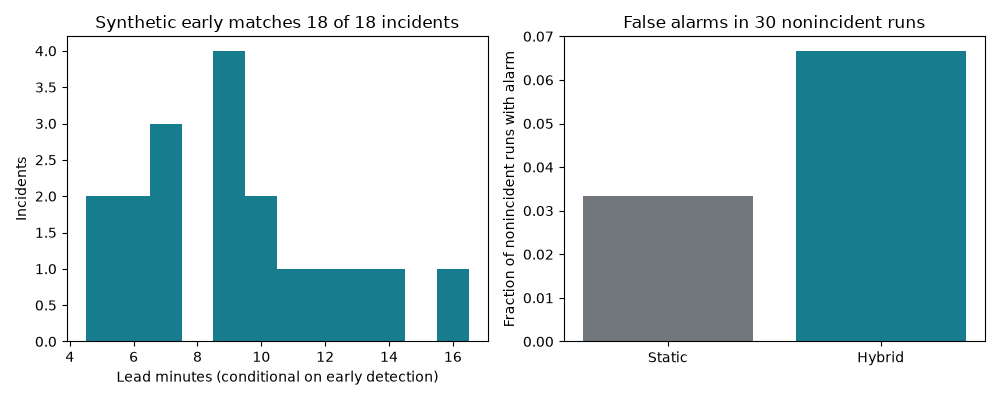

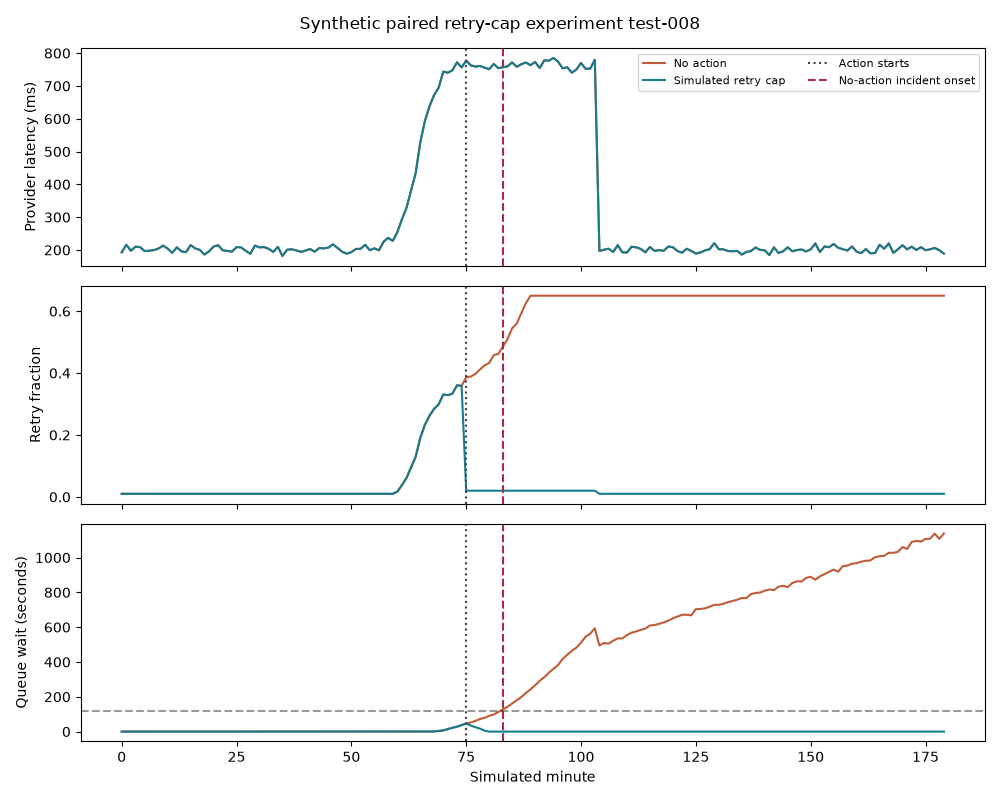

In [5]:
results = json.loads((ROOT / "reports/evaluation/synthetic_results.json").read_text())
display(pd.DataFrame([x for x in results if x["partition"] == "test"]))
display(pd.read_csv(ROOT / "reports/evaluation/synthetic_detection_by_kind.csv"))
display(pd.read_csv(ROOT / "reports/evaluation/paired_intervention_results.csv"))
display(Image(filename=str(ROOT / "reports/evaluation/figures/lead_and_false_alarms.png")))
display(Image(filename=str(ROOT / "reports/evaluation/figures/paired_demo.png")))

## Verification and limits

The checks cover byte-identical source copy, point baseline counts, disjoint seeds, exact synthetic regeneration, causal-prefix consistency, unchanged pre-action worlds and JSON schema/link/image integrity. They do not establish deployed agent behavior, LLM summary quality, live action safety or cloud throughput. Those remain explicit gates in the implementation plan.

In [6]:
check = subprocess.run([sys.executable, str(ROOT / "src/validate_artifacts.py")], cwd=ROOT, check=True, capture_output=True, text=True)
print(check.stdout)
display(pd.Series(json.loads((ROOT / "reports/evaluation/measurement_status.json").read_text()), name="measurement_status"))

{
  "passed": true,
  "checks_run": 223,
  "figure_count": 9,
  "scope": "Artifact integrity and statistical/simulation invariants only; no deployed application, model quality, agent action, or cloud checks."
}



organizer_point_baselines                     executed
synthetic_temporal_detector                   executed
paired_simulated_retry_cap                    executed
llm_summary_quality             not_run_no_model_calls
historical_retrieval               not_run_design_only
agent_workflow                         not_implemented
real_action_quality                            not_run
cloud_latency_and_throughput              not_deployed
measured_model_tokens_cost                     not_run
Name: measurement_status, dtype: object